# Flavor Change Clusters: Combinatorial Patterns in LLM Decision-Making

Analyzes **all** flavor changes across LLM-controlled players using a
two-track approach:

- **Single-flavor changes** (1 flavor) — simple frequency and effectiveness summary
- **Multi-flavor changes** (≥2 flavors) — L2-normalized and clustered with HDBSCAN
  to discover recurring *combinatorial* adjustment patterns

Pipeline:
1. **Detection** — identify all turns with nonzero flavor deltas
2. **Descriptive statistics** — frequency, magnitude, top flavors
3. **Single-flavor track** — which individual tweaks help/hurt
4. **Combinatorial clustering** — HDBSCAN on normalized multi-flavor deltas
5. **Cluster profiling** — centroid heatmaps and co-occurrence structure
6. **Effectiveness** — which combinatorial patterns improve win probability
7. **Cross-analysis** — by player type, game phase, strategy

In [ ]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import normalize
import hdbscan
import umap

from shared.plot_utilities import (
    setup_notebook_display,
    load_turn_data,
    forward_fill_strategy,
    detect_all_flavor_changes,
    compute_post_pivot_win_prob,
    classify_pivots,
    sort_player_types,
    get_player_color,
)

setup_notebook_display(figsize=(14, 6))

In [28]:
# Load data, merge win-probability predictions, filter to LLM players
df = load_turn_data("../turn_data.csv", exclude_non_llm=True)
pred = pd.read_csv("../models/output/attention_mlp_predictions.csv")
df = df.merge(
    pred[["game_id", "player_id", "turn", "predicted_win_probability"]],
    on=["game_id", "player_id", "turn"],
    how="left",
)
df = df[df["player_type"] != "Vanilla"].copy()
df_sorted = df.sort_values(["game_id", "player_id", "turn"])
forward_fill_strategy(df_sorted)

# Detect ALL flavor changes (not just strategy pivots)
changes, flavor_cols = detect_all_flavor_changes(df_sorted)
delta_cols = [f"{c}_delta" for c in flavor_cols]
flavor_short = [c.replace("flavor_", "") for c in flavor_cols]

print(f"LLM turns:                {len(df_sorted):,}")
print(f"Flavor change events:     {len(changes):,}")
print(f"  ({len(changes)/len(df_sorted)*100:.1f}% of all turns)")
print(f"Mean flavors changed/event: {changes['n_flavors_changed'].mean():.1f}")

d:\Cache\Onedrive - Arizona\OneDrive - University of Arizona\Vox Deorum\nlp-2026-tiny-4player\analysis\behaviors\..\plot_utilities.py:825: DtypeWarning: Columns (71) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


✓ Loaded turn data: 1039896 rows
✓ Filters applied: exclude_non_llm=True
✓ Unique conditions: 13
✓ Unique player types: 15
✓ Turn range: 0 - 500
✓ Unique civilizations: 43

Player Type Distribution:
  Vanilla: 330508 rows (31.8%)
  GLM-4.7-Simple: 75725 rows (7.3%)
  GLM-4.7-Briefed: 75725 rows (7.3%)
  Kimi-K2.5-Simple: 71134 rows (6.8%)
  Kimi-K2.5-Briefed: 71134 rows (6.8%)
  GPT-OSS-120B-Briefed: 65948 rows (6.3%)
  GPT-OSS-120B-Simple: 65948 rows (6.3%)
  Minimax-M2.5-Simple: 50112 rows (4.8%)
  Minimax-M2.5-Briefed: 50112 rows (4.8%)
  Deepseek-3.2-Briefed: 49080 rows (4.7%)
  Deepseek-3.2-Simple: 49080 rows (4.7%)
  Qwen-3.5-Briefed: 31503 rows (3.0%)
  Qwen-3.5-Simple: 31503 rows (3.0%)
  Sonnet-4.5-Briefed: 11192 rows (1.1%)
  Sonnet-4.5-Simple: 11192 rows (1.1%)

Condition Distribution:
  2026-deepseek-v-kimi2-v-glm-standard: 281688 rows (27.1%)
  2026-oss-v-glm-standard: 223776 rows (21.5%)
  2026-qwen-v-kimi2-v-minimax-standard: 132024 rows (12.7%)
  2026-oss-v-qwen-v-minim

## Section 1: Flavor Change Frequency and Magnitude

How often do LLMs adjust flavors (per game), and which flavors move the most?

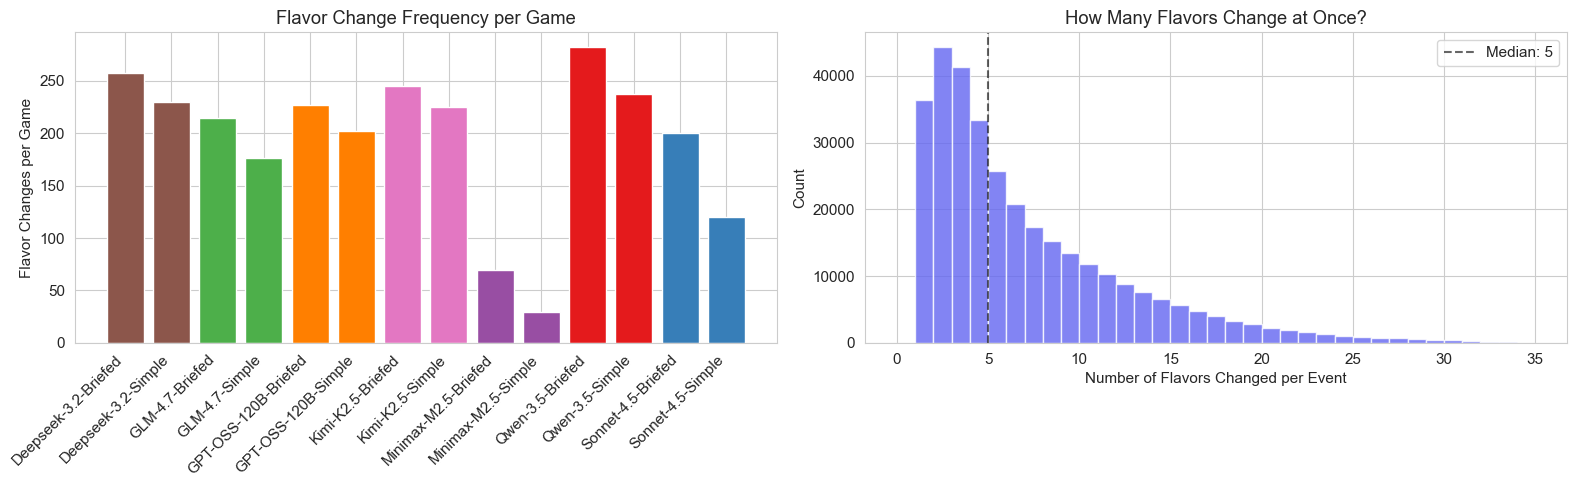

                      n_games  n_changes  changes_per_game
player_type                                               
Deepseek-3.2-Briefed      115      29582        257.234783
Deepseek-3.2-Simple       115      26469        230.165217
GLM-4.7-Briefed           179      38418        214.625698
GLM-4.7-Simple            179      31555        176.284916
GPT-OSS-120B-Briefed      145      32934        227.131034
GPT-OSS-120B-Simple       145      29298        202.055172
Kimi-K2.5-Briefed         167      40981        245.395210
Kimi-K2.5-Simple          167      37647        225.431138
Minimax-M2.5-Briefed      118       8250         69.915254
Minimax-M2.5-Simple       118       3478         29.474576
Qwen-3.5-Briefed           74      20883        282.202703
Qwen-3.5-Simple            74      17597        237.797297
Sonnet-4.5-Briefed         28       5616        200.571429
Sonnet-4.5-Simple          28       3357        119.892857


In [29]:
# Flavor changes per game by player type
games_per_model = df_sorted.groupby("player_type")["game_id"].nunique().rename("n_games")
change_counts = changes.groupby("player_type").size().rename("n_changes")
freq = pd.concat([games_per_model, change_counts], axis=1).fillna(0)
freq["changes_per_game"] = freq["n_changes"] / freq["n_games"]
player_order = sort_player_types(freq.index)
freq = freq.loc[player_order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

colors = [get_player_color(pt) for pt in player_order]
ax1.bar(range(len(player_order)), freq["changes_per_game"], color=colors)
ax1.set_xticks(range(len(player_order)))
ax1.set_xticklabels(player_order, rotation=45, ha="right")
ax1.set_ylabel("Flavor Changes per Game")
ax1.set_title("Flavor Change Frequency per Game")

# Distribution of n_flavors_changed per event
ax2.hist(changes["n_flavors_changed"], bins=range(0, 36), color="#6366F1",
         alpha=0.8, edgecolor="white")
ax2.set_xlabel("Number of Flavors Changed per Event")
ax2.set_ylabel("Count")
ax2.set_title("How Many Flavors Change at Once?")
ax2.axvline(changes["n_flavors_changed"].median(), color="black", ls="--",
            alpha=0.6, label=f'Median: {changes["n_flavors_changed"].median():.0f}')
ax2.legend()

plt.tight_layout()
plt.show()

print(freq[["n_games", "n_changes", "changes_per_game"]].to_string())

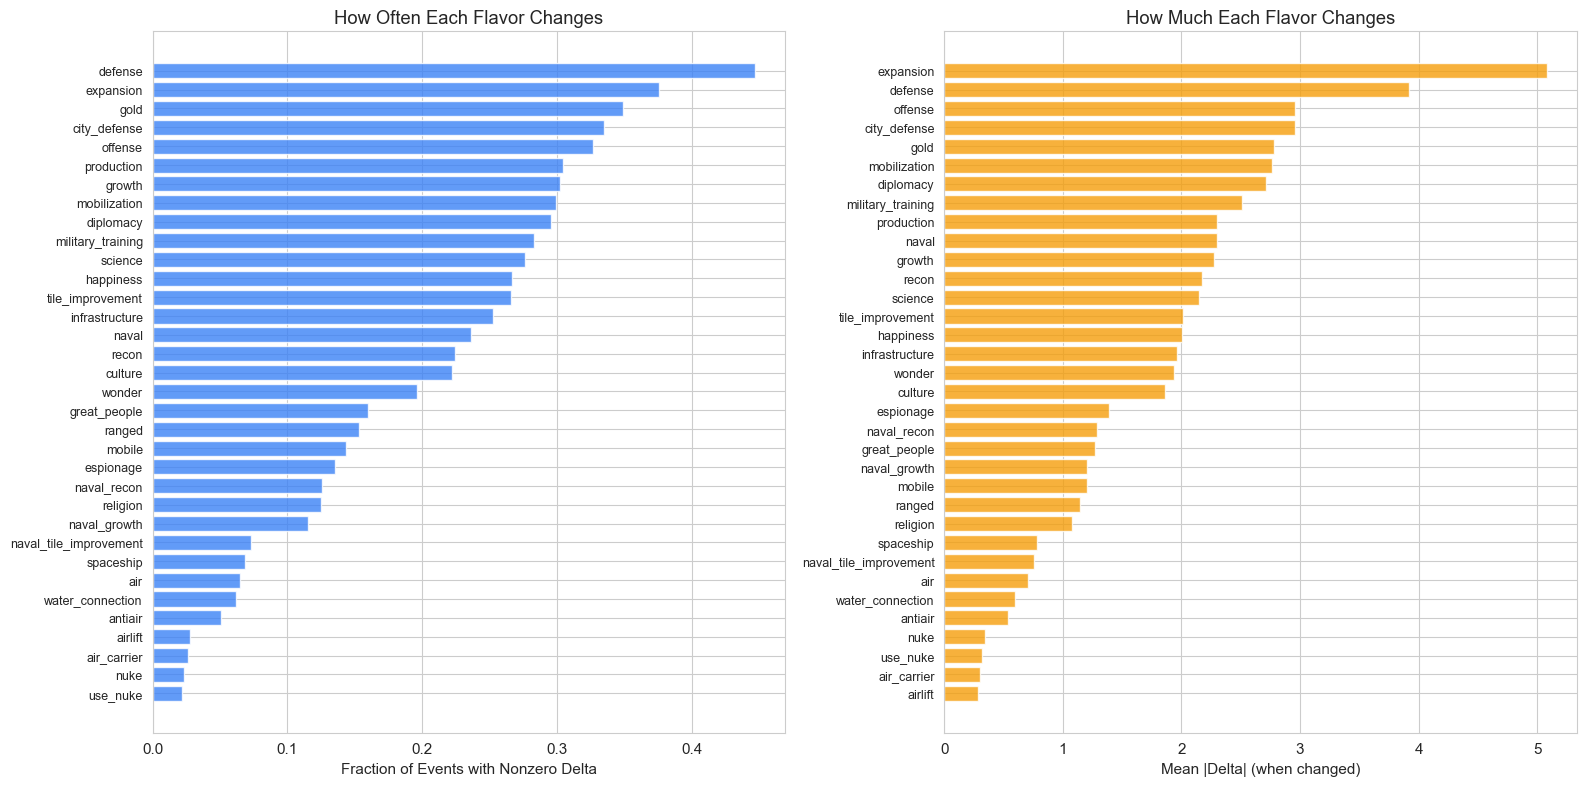

In [30]:
# Top flavors by change frequency and mean absolute delta
change_freq = (changes[delta_cols].abs() > 0).mean().values
mean_abs_delta = changes[delta_cols].abs().mean().values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

order = np.argsort(change_freq)[::-1]
ax1.barh(range(len(flavor_short)), change_freq[order], color="#3B82F6", alpha=0.8)
ax1.set_yticks(range(len(flavor_short)))
ax1.set_yticklabels([flavor_short[i] for i in order], fontsize=9)
ax1.set_xlabel("Fraction of Events with Nonzero Delta")
ax1.set_title("How Often Each Flavor Changes")
ax1.invert_yaxis()

order2 = np.argsort(mean_abs_delta)[::-1]
ax2.barh(range(len(flavor_short)), mean_abs_delta[order2], color="#F59E0B", alpha=0.8)
ax2.set_yticks(range(len(flavor_short)))
ax2.set_yticklabels([flavor_short[i] for i in order2], fontsize=9)
ax2.set_xlabel("Mean |Delta| (when changed)")
ax2.set_title("How Much Each Flavor Changes")
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

## Section 2: Single-Flavor Changes

Events where exactly one flavor changed have no combinatorial structure —
a simple frequency table and effectiveness summary suffices. We separate
these from multi-flavor events (≥2 flavors), which are the focus of clustering.

Single-flavor events:   36,423 (11.2%)
Multi-flavor events:   289,642 (88.8%)
Total:                 326,065


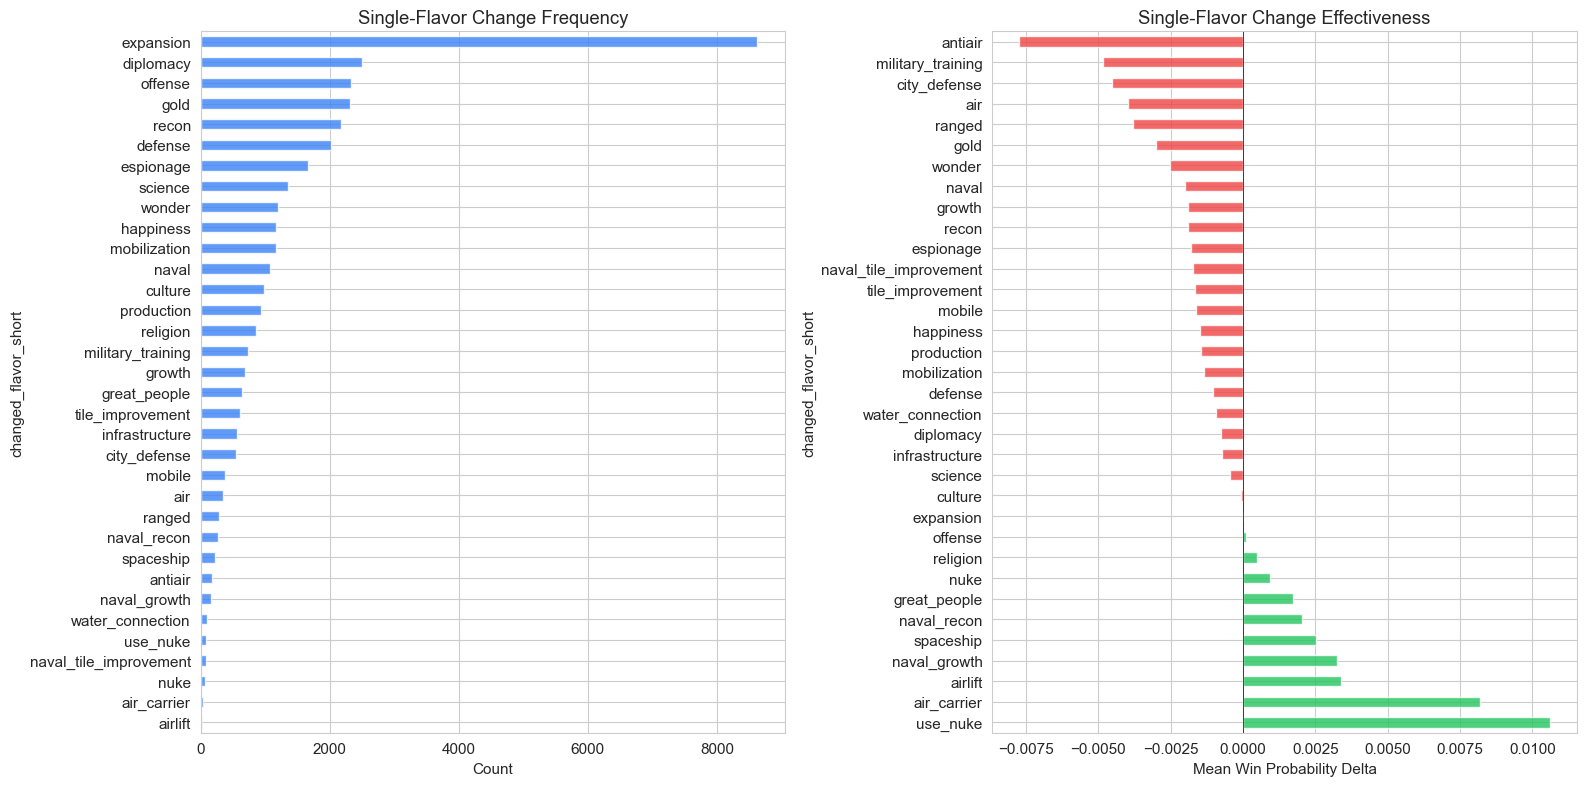


Top 5 most effective single-flavor changes:
              use_nuke: +0.0106  (n=85)
           air_carrier: +0.0082  (n=42)
               airlift: +0.0034  (n=17)
          naval_growth: +0.0033  (n=163)
             spaceship: +0.0025  (n=225)

Top 5 least effective single-flavor changes:
               antiair: -0.0077  (n=170)
     military_training: -0.0049  (n=742)
          city_defense: -0.0045  (n=544)
                   air: -0.0040  (n=347)
                ranged: -0.0038  (n=292)


In [ ]:
# Split single-flavor vs multi-flavor events
single = changes[changes["n_flavors_changed"] == 1].copy()
multi = changes[changes["n_flavors_changed"] >= 2].copy()

print(f"Single-flavor events: {len(single):>8,} ({len(single)/len(changes):.1%})")
print(f"Multi-flavor events:  {len(multi):>8,} ({len(multi)/len(changes):.1%})")
print(f"Total:                {len(changes):>8,}")

# Compute effectiveness for ALL changes once, propagate to both subsets
changes["before_prob"] = changes["predicted_win_probability"]
changes["after_prob"] = compute_post_pivot_win_prob(changes, df_sorted, window=50)
changes["win_prob_delta"] = changes["after_prob"] - changes["before_prob"]
classify_pivots(changes, threshold=0.05)

for col in ["before_prob", "after_prob", "win_prob_delta", "impact_class"]:
    single[col] = changes.loc[single.index, col]
    multi[col] = changes.loc[multi.index, col]

# Identify which flavor changed in single-flavor events
single["changed_flavor"] = (single[delta_cols].abs() > 0).idxmax(axis=1)
single["changed_flavor_short"] = (
    single["changed_flavor"].str.replace("flavor_", "").str.replace("_delta", "")
)

# --- Single-flavor frequency bar chart ---
flavor_counts = single["changed_flavor_short"].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

flavor_counts.plot.barh(ax=ax1, color="#3B82F6", alpha=0.8)
ax1.set_xlabel("Count")
ax1.set_title("Single-Flavor Change Frequency")
ax1.invert_yaxis()

# --- Single-flavor effectiveness ---
eff = single.dropna(subset=["win_prob_delta"]).groupby("changed_flavor_short")
mean_delta = eff["win_prob_delta"].mean().sort_values()
colors = ["#22C55E" if v > 0 else "#EF4444" for v in mean_delta.values]
mean_delta.plot.barh(ax=ax2, color=colors, alpha=0.8)
ax2.axvline(0, color="black", lw=0.5)
ax2.set_xlabel("Mean Win Probability Delta")
ax2.set_title("Single-Flavor Change Effectiveness")
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

# Top effective / ineffective single-flavor changes
print("\nTop 5 most effective single-flavor changes:")
for name, val in mean_delta.tail(5).iloc[::-1].items():
    n = flavor_counts.get(name, 0)
    print(f"  {name:>20s}: {val:+.4f}  (n={n:,})")
print("\nTop 5 least effective single-flavor changes:")
for name, val in mean_delta.head(5).items():
    n = flavor_counts.get(name, 0)
    print(f"  {name:>20s}: {val:+.4f}  (n={n:,})")

In [ ]:
# --- Co-occurrence Jaccard heatmap (all multi-flavor events) ---
# Shows which flavors tend to change together, motivating the clustering that follows.
binary = (multi[delta_cols].abs() > 0).astype(int).values  # (N, 34)
cooccurrence = binary.T @ binary  # (34, 34)

# Jaccard similarity: |A∩B| / |A∪B|
diag = np.diag(cooccurrence).astype(float)
union = diag[:, None] + diag[None, :] - cooccurrence
jaccard = np.divide(
    cooccurrence, union, where=union > 0,
    out=np.zeros_like(cooccurrence, dtype=float),
)
np.fill_diagonal(jaccard, 0)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    jaccard,
    xticklabels=flavor_short, yticklabels=flavor_short,
    cmap="YlOrRd", ax=ax, vmin=0, square=True,
    linewidths=0.3,
)
ax.set_title("Flavor Co-occurrence (Jaccard Similarity, Multi-Flavor Events)")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# L2-normalize multi-flavor delta vectors for combinatorial clustering
# On unit vectors, Euclidean distance is monotonically related to cosine distance:
#   ||a - b||^2 = 2(1 - cos(a, b))
# This lets HDBSCAN find directional patterns (which flavors co-move) rather than
# magnitude patterns (which single flavor moved the most).

X_raw = multi[delta_cols].fillna(0).values
X_norm = normalize(X_raw, norm="l2", axis=1)

print(f"Multi-flavor events to cluster: {len(X_norm):,}")
print(f"Dimensions: {X_norm.shape[1]}")

# HDBSCAN on normalized vectors
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=200,
    min_samples=20,
    metric="euclidean",
    cluster_selection_method="leaf",
)
clusterer.fit(X_norm)
multi["cluster"] = clusterer.labels_

n_clusters = multi["cluster"].max() + 1
n_noise = (multi["cluster"] == -1).sum()
print(f"\nClusters found: {n_clusters}")
print(f"Noise points: {n_noise:,} ({n_noise/len(multi):.1%})")
print(f"\nCluster sizes:")
print(multi[multi["cluster"] >= 0]["cluster"].value_counts().sort_index().to_string())

# UMAP for visualization (cosine metric matches the normalized-vector logic)
reducer = umap.UMAP(n_components=2, metric="cosine", random_state=42)
X_umap = reducer.fit_transform(X_norm)

fig, ax = plt.subplots(figsize=(10, 8))

cluster_ids = sorted(multi["cluster"].unique())
noise_mask = multi["cluster"].values == -1
if noise_mask.any():
    ax.scatter(X_umap[noise_mask, 0], X_umap[noise_mask, 1],
               alpha=0.05, s=2, c="lightgrey", label="Noise")
cmap_sc = plt.cm.tab10
for c in [cid for cid in cluster_ids if cid >= 0]:
    mask = multi["cluster"].values == c
    ax.scatter(X_umap[mask, 0], X_umap[mask, 1], alpha=0.15, s=4,
               color=cmap_sc(c % 10), label=f"Cluster {c}")
ax.legend(markerscale=5, fontsize=9)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP of Normalized Flavor Deltas (by HDBSCAN Cluster)")

plt.tight_layout()
plt.show()

## Section 3: Combinatorial Cluster Profiles

What characterizes each cluster? The centroid heatmap uses **normalized** vectors
so it shows the directional pattern (which flavors co-move) rather than raw magnitude.
The co-occurrence heatmap shows which flavors structurally change together across
all multi-flavor events.

In [ ]:
# Cluster profile table: top changed flavors + summary stats per cluster
clustered_multi = multi[multi["cluster"] >= 0].copy()
real_clusters = sorted(clustered_multi["cluster"].unique())

# Build normalized-vector DataFrame aligned with multi's index
norm_df = pd.DataFrame(X_norm, columns=delta_cols, index=multi.index)
norm_df["cluster"] = multi["cluster"].values

if len(real_clusters) >= 1:
    cluster_means_norm = norm_df[norm_df["cluster"] >= 0].groupby("cluster")[delta_cols].mean()

    rows = []
    for c in real_clusters:
        subset = clustered_multi[clustered_multi["cluster"] == c]
        centroid = cluster_means_norm.loc[c]
        top = centroid.abs().nlargest(8)
        flavors_str = ", ".join(
            f"{idx.replace('flavor_', '').replace('_delta', '')} "
            f"({'+'if centroid[idx] > 0 else ''}{centroid[idx]:.3f})"
            for idx in top.index
        )
        strat_dist = subset["strategy_filled"].value_counts(normalize=True)
        strat_str = ", ".join(f"{s}: {v:.0%}" for s, v in strat_dist.items())
        rows.append({
            "Cluster": c,
            "Size": len(subset),
            "Mean #Chg": f"{subset['n_flavors_changed'].mean():.1f}",
            "Strategy Mix": strat_str,
            "Top Changed Flavors (normalized centroid)": flavors_str,
        })

    # Append noise row
    noise = multi[multi["cluster"] == -1]
    if len(noise):
        strat_dist = noise["strategy_filled"].value_counts(normalize=True)
        strat_str = ", ".join(f"{s}: {v:.0%}" for s, v in strat_dist.items())
        rows.append({
            "Cluster": "Noise",
            "Size": len(noise),
            "Mean #Chg": f"{noise['n_flavors_changed'].mean():.1f}",
            "Strategy Mix": strat_str,
            "Top Changed Flavors (normalized centroid)": "—",
        })

    profile_df = pd.DataFrame(rows).set_index("Cluster")
    pd.set_option("display.max_colwidth", 120)
    print(profile_df.to_string())
else:
    print("No clusters found — all points classified as noise.")

## Section 4: Effectiveness Analysis

Which flavor change clusters correlate with improved win probability?
Uses the attention MLP's predicted win probability before and after
each change event (50-turn linear-decay weighted window).

In [ ]:
# Effectiveness was already computed in Section 2 and propagated to multi.
# Just report stats for the multi-flavor clustered events.
n_with_delta = multi["win_prob_delta"].notna().sum()
print(f"Multi-flavor events with win_prob_delta: {n_with_delta:,} / {len(multi):,}")
print(f"\nImpact class distribution (multi-flavor changes):")
print(multi["impact_class"].value_counts().to_string())

Multi-flavor events with win_prob_delta: 289,338 / 289,642

Impact class distribution (multi-flavor changes):
impact_class
neutral             243857
very_effective       23056
very_ineffective     22729


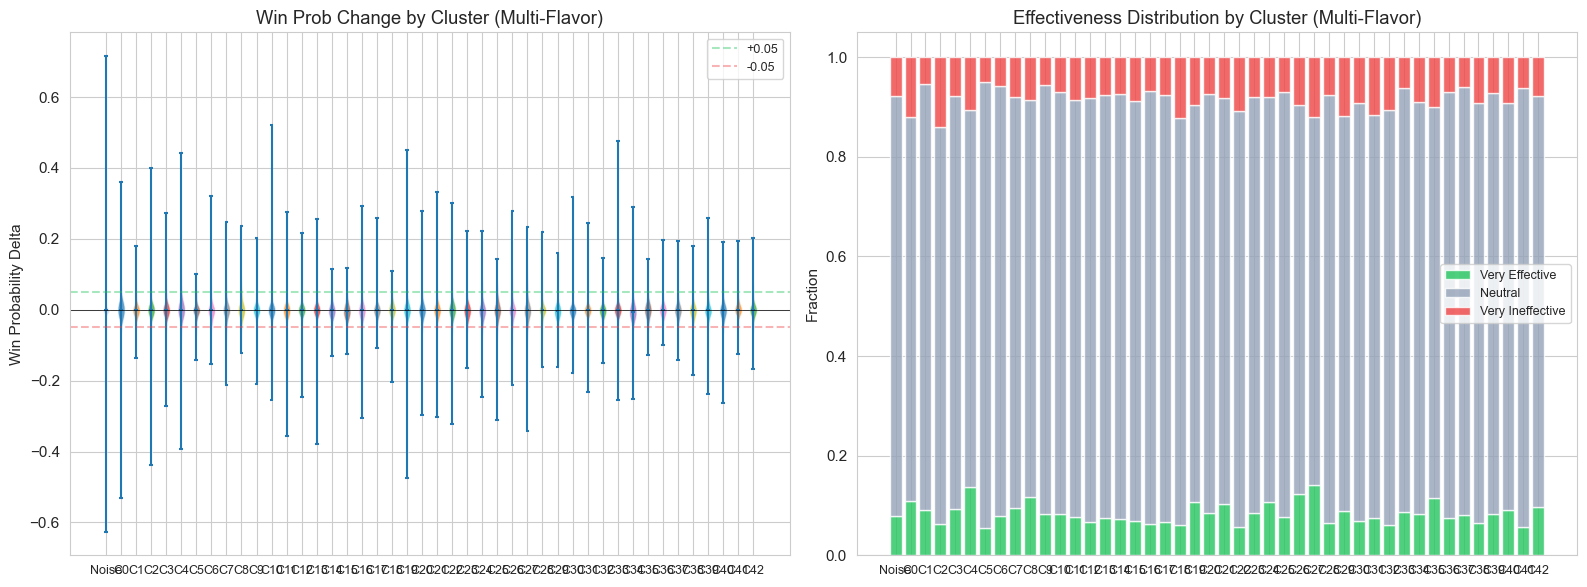


Mean win_prob_delta by cluster:
             mean        median   count
cluster                                
-1      -0.001610 -2.055532e-04  272388
 0      -0.003505 -5.056196e-07     302
 1       0.002305 -1.241894e-04     397
 2      -0.010031 -1.754155e-05     533
 3       0.000568 -2.001471e-05     410
 4       0.003672 -4.692792e-05     445
 5      -0.000591 -2.932855e-05     276
 6      -0.000910 -3.669325e-04     345
 7      -0.000759 -8.994443e-06     404
 8       0.003600 -2.537168e-06     222
 9       0.001630 -5.759296e-06     305
 10      0.001309 -5.922109e-05     668
 11     -0.001555 -2.319440e-04     302
 12     -0.002379 -3.460182e-05     401
 13     -0.000089 -8.683366e-05     651
 14     -0.001723 -9.567464e-04     232
 15     -0.003661 -2.244124e-03     206
 16     -0.003451 -2.527495e-04     251
 17     -0.001754 -7.557279e-05     209
 18     -0.004731 -2.234566e-04     228
 19     -0.000841 -5.153113e-05     810
 20      0.000514 -5.227658e-04     510
 21    

In [ ]:
# Win prob delta distribution by cluster (include noise as its own group)
has_delta = multi.dropna(subset=["win_prob_delta"])
all_labels = sorted(has_delta["cluster"].unique())
display_labels = ["Noise" if c == -1 else f"C{c}" for c in all_labels]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Violin plot
violin_data = [has_delta[has_delta["cluster"] == c]["win_prob_delta"].values
               for c in all_labels]
positions = range(len(all_labels))
parts = ax1.violinplot(violin_data, positions=positions, showmedians=True)
cmap_v = plt.cm.tab10
for i, pc in enumerate(parts["bodies"]):
    pc.set_facecolor("lightgray" if all_labels[i] == -1 else cmap_v(all_labels[i] % 10))
    pc.set_alpha(0.7)
ax1.axhline(0, color="black", lw=0.5)
ax1.axhline(0.05, color="#22C55E", ls="--", alpha=0.4, label="+0.05")
ax1.axhline(-0.05, color="#EF4444", ls="--", alpha=0.4, label="-0.05")
ax1.set_xticks(positions)
ax1.set_xticklabels(display_labels, fontsize=9)
ax1.set_ylabel("Win Probability Delta")
ax1.set_title("Win Prob Change by Cluster (Multi-Flavor)")
ax1.legend(fontsize=9)

# Effectiveness stacked bar
eff_by_cluster = has_delta.groupby(["cluster", "impact_class"]).size().unstack(fill_value=0)
eff_pct = eff_by_cluster.div(eff_by_cluster.sum(axis=1), axis=0)
color_map = {"very_effective": "#22C55E", "neutral": "#94A3B8", "very_ineffective": "#EF4444"}
x_pos = range(len(eff_pct))
bottom = np.zeros(len(eff_pct))
for cls in ["very_effective", "neutral", "very_ineffective"]:
    if cls in eff_pct.columns:
        vals = eff_pct[cls].values
        ax2.bar(x_pos, vals, bottom=bottom, color=color_map[cls],
                label=cls.replace("_", " ").title(), alpha=0.8)
        bottom += vals
ax2.set_xticks(x_pos)
ax2.set_xticklabels(["Noise" if c == -1 else f"C{c}" for c in eff_pct.index], fontsize=9)
ax2.set_ylabel("Fraction")
ax2.set_title("Effectiveness Distribution by Cluster (Multi-Flavor)")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Stats
print("\nMean win_prob_delta by cluster:")
print(has_delta.groupby("cluster")["win_prob_delta"].agg(["mean", "median", "count"]).to_string())
non_noise = [v for c, v in zip(all_labels, violin_data) if c >= 0 and len(v) > 0]
if len(non_noise) >= 2:
    stat, p = stats.kruskal(*non_noise)
    print(f"\nKruskal-Wallis (clusters only, excl. noise): H={stat:.1f}, p={p:.2e}")

## Section 5: Cross-Analysis

How do clusters distribute across player types, game phases, and strategies?
Do certain cluster sequences emerge within a player's game?

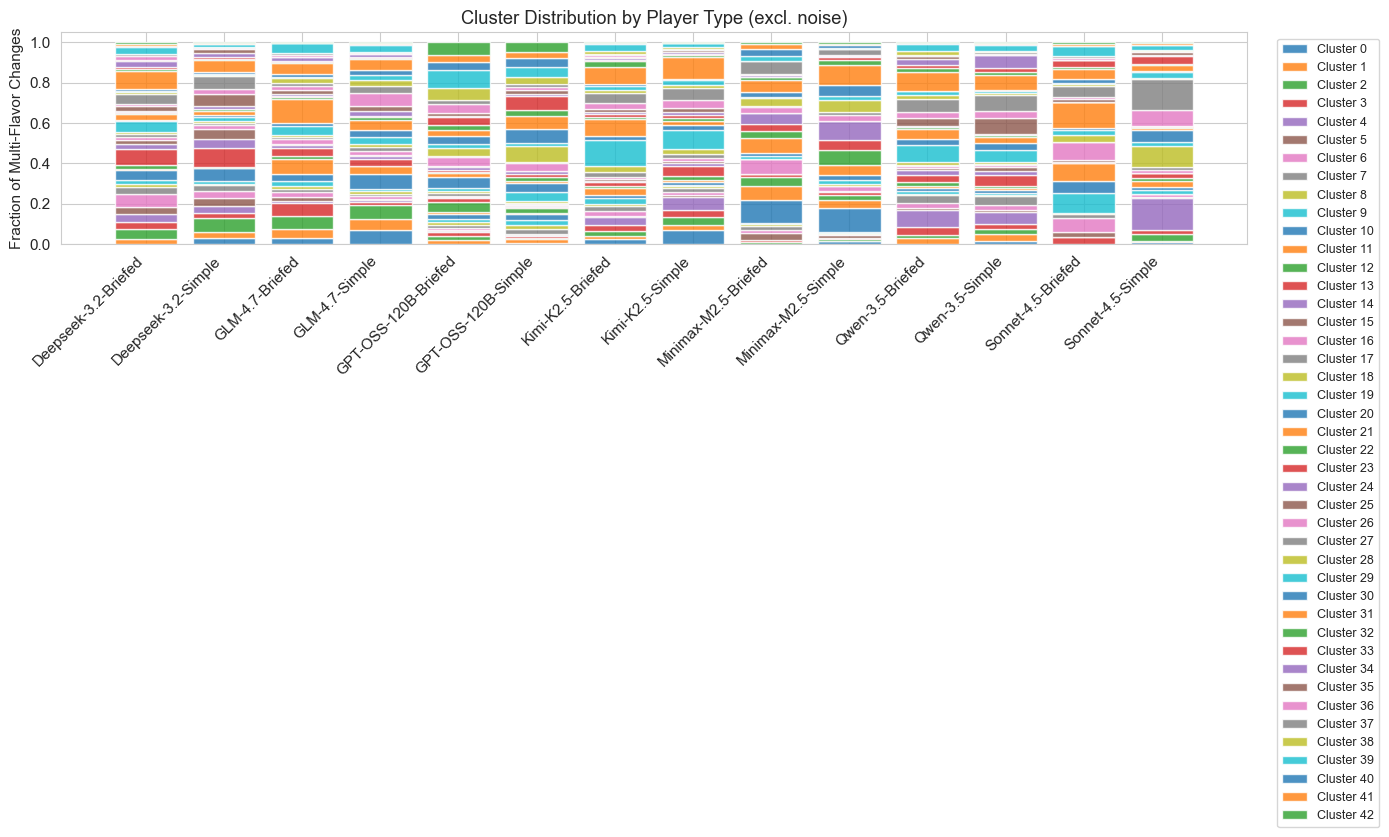

In [ ]:
# Cluster distribution by player type (normalized stacked bar, excl. noise)
player_order = sort_player_types(clustered_multi["player_type"].unique())
ct = pd.crosstab(clustered_multi["player_type"], clustered_multi["cluster"], normalize="index")
ct = ct.loc[[p for p in player_order if p in ct.index]]

fig, ax = plt.subplots(figsize=(14, 6))
bottom = np.zeros(len(ct))
cmap_bar = plt.cm.tab10
for c in real_clusters:
    if c in ct.columns:
        vals = ct[c].values
        ax.bar(range(len(ct)), vals, bottom=bottom, label=f"Cluster {c}",
               color=cmap_bar(c % 10), alpha=0.8)
        bottom += vals
ax.set_xticks(range(len(ct)))
ax.set_xticklabels(ct.index, rotation=45, ha="right")
ax.set_ylabel("Fraction of Multi-Flavor Changes")
ax.set_title("Cluster Distribution by Player Type (excl. noise)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

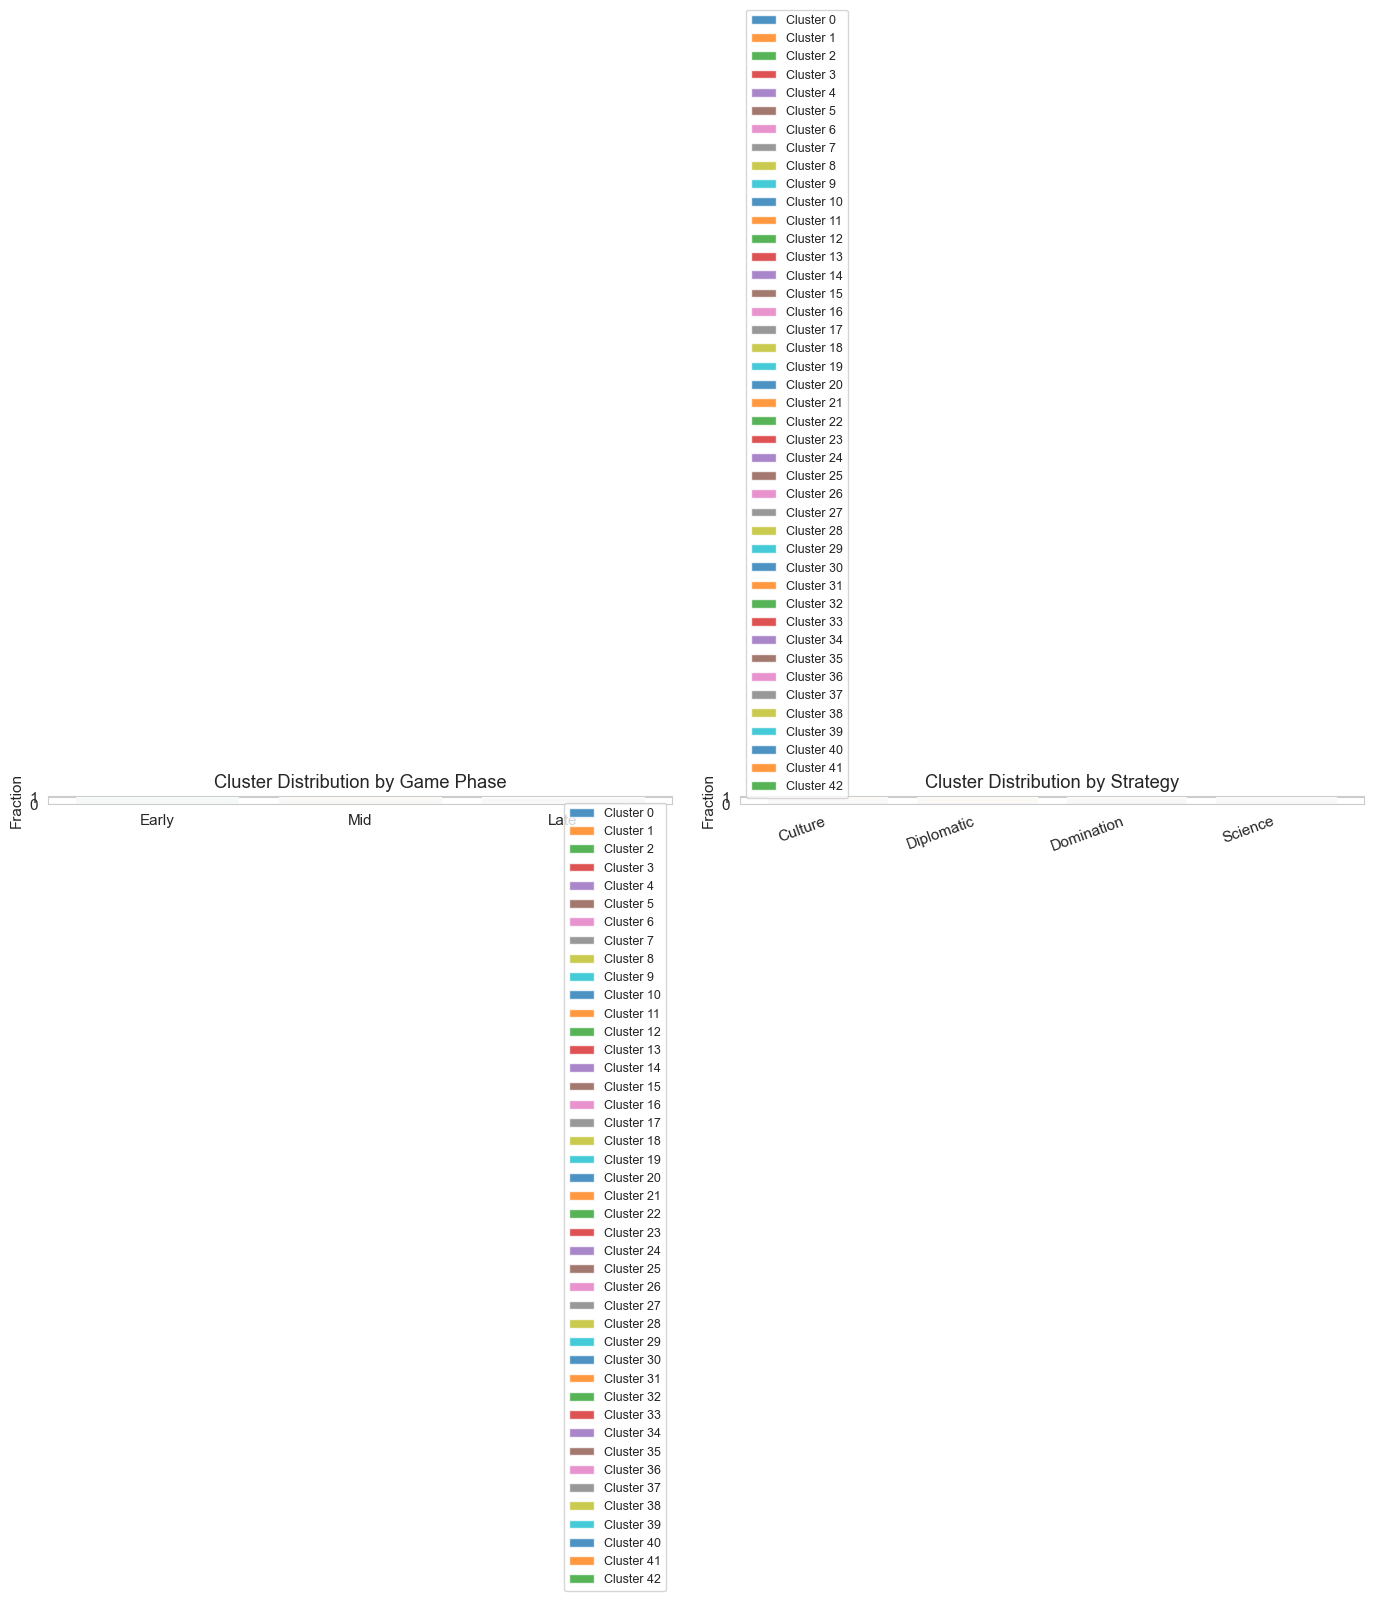

In [ ]:
# Cluster distribution by game phase and strategy (excl. noise)
clustered_multi = clustered_multi.copy()
clustered_multi["turn_progress"] = clustered_multi["turn"] / clustered_multi["max_turn"]
clustered_multi["game_phase"] = pd.cut(
    clustered_multi["turn_progress"], bins=[0, 1/3, 2/3, 1.01],
    labels=["Early", "Mid", "Late"],
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
cmap_bar = plt.cm.tab10

ct_phase = pd.crosstab(clustered_multi["game_phase"], clustered_multi["cluster"], normalize="index")
bottom = np.zeros(len(ct_phase))
for c in real_clusters:
    if c in ct_phase.columns:
        vals = ct_phase[c].values
        ax1.bar(range(len(ct_phase)), vals, bottom=bottom, label=f"Cluster {c}",
                color=cmap_bar(c % 10), alpha=0.8)
        bottom += vals
ax1.set_xticks(range(len(ct_phase)))
ax1.set_xticklabels(ct_phase.index)
ax1.set_ylabel("Fraction")
ax1.set_title("Cluster Distribution by Game Phase")
ax1.legend(fontsize=9)

ct_strat = pd.crosstab(clustered_multi["strategy_filled"], clustered_multi["cluster"], normalize="index")
bottom = np.zeros(len(ct_strat))
for c in real_clusters:
    if c in ct_strat.columns:
        vals = ct_strat[c].values
        ax2.bar(range(len(ct_strat)), vals, bottom=bottom, label=f"Cluster {c}",
                color=cmap_bar(c % 10), alpha=0.8)
        bottom += vals
ax2.set_xticks(range(len(ct_strat)))
ax2.set_xticklabels(ct_strat.index, rotation=20, ha="right")
ax2.set_ylabel("Fraction")
ax2.set_title("Cluster Distribution by Strategy")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

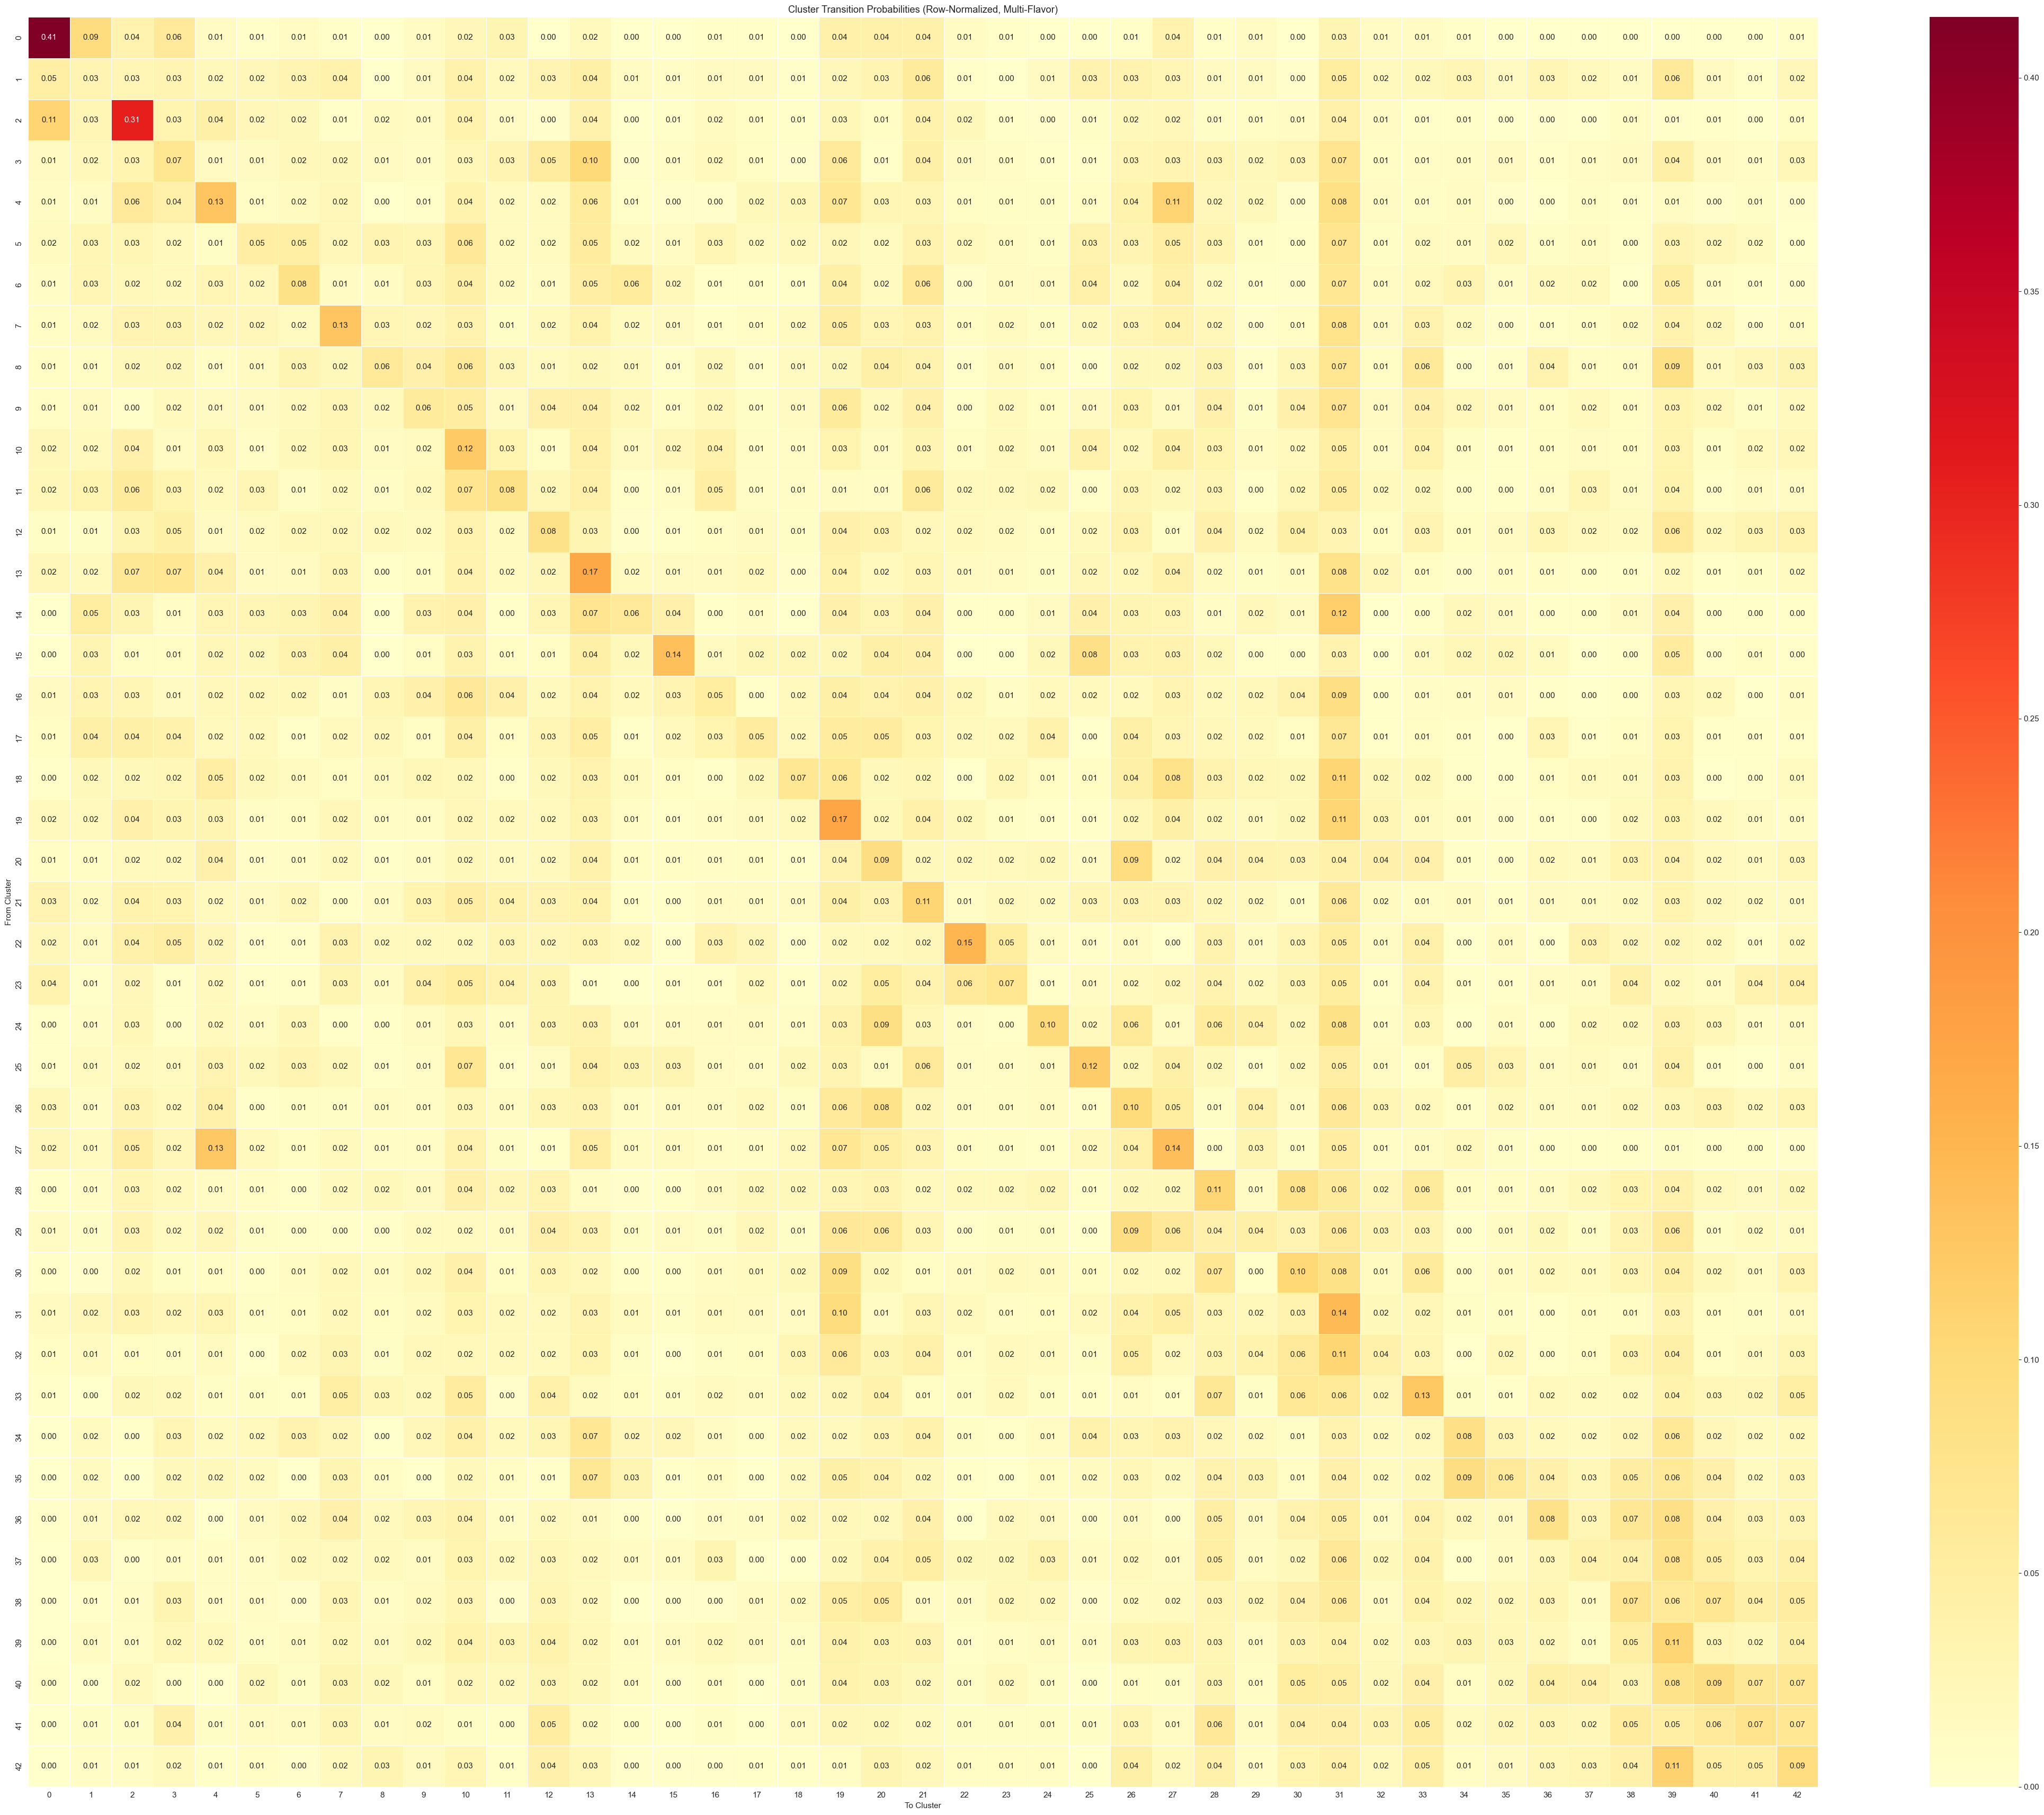

In [ ]:
# Cluster transition heatmap (excl. noise): for consecutive multi-flavor changes
# within the same player-game, how often does cluster X follow cluster Y?
if len(real_clusters) >= 2:
    clustered_sorted = clustered_multi.sort_values(["game_id", "player_id", "turn"])
    prev_cluster = clustered_sorted.groupby(["game_id", "player_id"])["cluster"].shift(1)
    valid = prev_cluster.notna()
    transitions = pd.crosstab(
        prev_cluster[valid].astype(int).rename("From Cluster"),
        clustered_sorted.loc[valid.values, "cluster"].rename("To Cluster"),
        normalize="index",
    )

    fig, ax = plt.subplots(figsize=(max(6, len(real_clusters)), max(5, len(real_clusters) * 0.8)))
    sns.heatmap(transitions, annot=True, fmt=".2f", cmap="YlOrRd",
                linewidths=0.5, ax=ax)
    ax.set_title("Cluster Transition Probabilities (Row-Normalized, Multi-Flavor)")
    plt.tight_layout()
    plt.show()
else:
    print("Transition heatmap requires ≥2 clusters. Skipped.")

## Section 6: Summary

In [ ]:
multi["turn_progress"] = multi["turn"] / multi["max_turn"]
multi["game_phase"] = pd.cut(
    multi["turn_progress"], bins=[0, 1/3, 2/3, 1.01],
    labels=["Early", "Mid", "Late"],
)

# Use normalized centroids for top-5 flavors (directional pattern)
summary_rows = []
for c in sorted(multi["cluster"].unique()):
    subset = multi[multi["cluster"] == c]
    label = "Noise" if c == -1 else str(c)

    if c >= 0 and len(real_clusters) >= 2:
        # Top 5 from normalized centroid
        norm_means = cluster_means_norm.loc[c]
        top5 = norm_means.abs().nlargest(5)
        top5_str = ", ".join(
            f"{idx.replace('flavor_','').replace('_delta','')}"
            f"({'+'if norm_means[idx]>0 else ''}{norm_means[idx]:.3f})"
            for idx in top5.index
        )
    else:
        # Noise or single cluster: use raw means
        means = subset[delta_cols].mean()
        top5 = means.abs().nlargest(5)
        top5_str = ", ".join(
            f"{idx.replace('flavor_','').replace('_delta','')}"
            f"({'+'if means[idx]>0 else ''}{means[idx]:.1f})"
            for idx in top5.index
        )

    sub_delta = subset["win_prob_delta"].dropna()
    top_strat = subset["strategy_filled"].mode().iloc[0] if len(subset) else "N/A"
    top_phase = subset["game_phase"].mode().iloc[0] if len(subset) else "N/A"
    summary_rows.append({
        "Cluster": label,
        "Size": len(subset),
        "Pct": f"{len(subset)/len(multi):.1%}",
        "Top 5 Flavors (normalized)": top5_str,
        "Mean WP Delta": f"{sub_delta.mean():+.4f}" if len(sub_delta) else "N/A",
        "Top Strategy": top_strat,
        "Top Phase": top_phase,
    })

summary_df = pd.DataFrame(summary_rows).set_index("Cluster")
pd.set_option("display.max_colwidth", 80)
print(summary_df.to_string())

           Size    Pct                                                                                 Top 5 Flavors (normalized) Mean WP Delta Top Strategy Top Phase
Cluster                                                                                                                                                               
Noise    272671  94.1%                                  expansion(-0.6), recon(-0.3), offense(-0.2), wonder(-0.2), religion(-0.2)       -0.0016      Science     Early
0           303   0.1%                              nuke(+0.725), use_nuke(+0.487), science(+0.017), air(+0.015), antiair(+0.012)       -0.0035   Domination      Late
1           397   0.1%                          nuke(-0.496), use_nuke(-0.460), air_carrier(-0.197), air(-0.192), antiair(-0.190)       +0.0023   Domination     Early
2           538   0.2%                         antiair(+0.561), air(+0.558), city_defense(+0.070), naval(+0.064), defense(+0.050)       -0.0100   Diplomatic      Lat